<a href="https://colab.research.google.com/github/FantinelBruna/pcd-unijui/blob/main/trabalho/projetoGrupo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise e previsão de aprovação de empréstimos bancários

**Fonte original:** [Loan Approval Prediction Dataset — Kaggle](https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset).
O CSV será lido por uma [cópia pública no GitHub](https://github.com/loh-0/Loan-Approval-Prediction/blob/main/data/loan_approval_dataset.csv) para facilitar a execução no Colab.

## 1. Obtenção dos dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/loh-0/Loan-Approval-Prediction/main/data/loan_approval_dataset.csv"
df = pd.read_csv(url)

print("Linhas e colunas:", df.shape)
print("\nDados:")
df.head()

Linhas e colunas: (4269, 13)

Dados:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## 2. Conhecendo e limpando os dados

In [2]:
df.columns = df.columns.str.strip()
for coluna in df.select_dtypes(include="object").columns:
    df[coluna] = df[coluna].str.strip()

print("Informações gerais:")
df.info()
print("\nValores ausentes por coluna:")
print(df.isnull().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB

Valores a

In [3]:
df = df.drop_duplicates().copy()

colunas_valores = [
    "income_annum", "loan_amount", "residential_assets_value",
    "commercial_assets_value", "luxury_assets_value", "bank_asset_value"
]

print("Quantidade de valores negativos por coluna:")
print((df[colunas_valores] < 0).sum())

for coluna in colunas_valores:
    df.loc[df[coluna] < 0, coluna] = float("nan")

antes = len(df)
df = df.dropna().copy()
print("\nLinhas antes:", antes)
print("Linhas removidas por valores ausentes ou inválidos:", antes - len(df))
print("Linhas restantes:", len(df))

Quantidade de valores negativos por coluna:
income_annum                 0
loan_amount                  0
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64

Linhas antes: 4269
Linhas removidas por valores ausentes ou inválidos: 28
Linhas restantes: 4241


## 3. Análise exploratória


In [4]:
print("Resumo das variáveis numéricas:")
display(df.describe().round(2))

print("Distribuição da aprovação:")
print(df["loan_status"].value_counts())
print("\nPorcentagens:")
print((df["loan_status"].value_counts(normalize=True) * 100).round(1))

Resumo das variáveis numéricas:


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4241.00,4241.0,4241.00,4241.00,4241.00,4241.00,4241.00,4241.00,4241.00,4241.00
mean,2134.50,2.5,5074251.36,15178401.32,10.90,599.69,7522612.59,4985121.43,15171209.62,4991487.86
std,1231.65,1.7,2803165.67,9034490.27,5.71,172.28,6495800.19,4391503.67,9094716.67,3249493.53
min,1.00,0.0,200000.00,300000.00,2.00,300.00,0.00,0.00,300000.00,0.00
25%,1068.00,1.0,2700000.00,7700000.00,6.00,453.00,2200000.00,1300000.00,7500000.00,2400000.00
50%,2137.00,3.0,5100000.00,14600000.00,10.00,600.00,5700000.00,3700000.00,14600000.00,4600000.00
75%,3201.00,4.0,7500000.00,21500000.00,16.00,747.00,11400000.00,7700000.00,21700000.00,7100000.00
max,4269.00,5.0,9900000.00,39500000.00,20.00,900.00,29100000.00,19400000.00,39200000.00,14700000.00


Distribuição da aprovação:
loan_status
Approved    2640
Rejected    1601
Name: count, dtype: int64

Porcentagens:
loan_status
Approved    62.2
Rejected    37.8
Name: proportion, dtype: float64


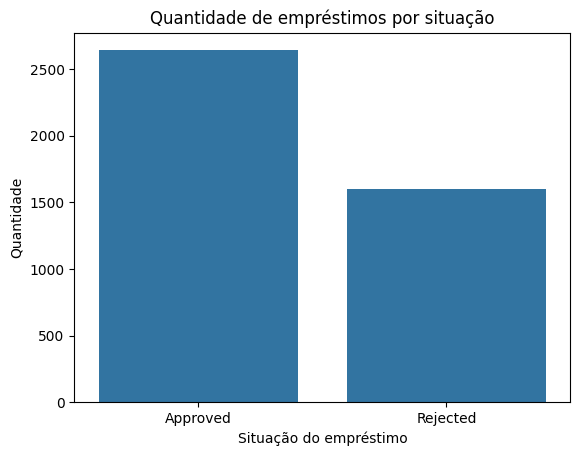

In [5]:
# Gráfico 1: quantidade de aprovados e rejeitados
sns.countplot(data=df, x="loan_status", order=["Approved", "Rejected"])
plt.title("Quantidade de empréstimos por situação")
plt.xlabel("Situação do empréstimo")
plt.ylabel("Quantidade")
plt.show()

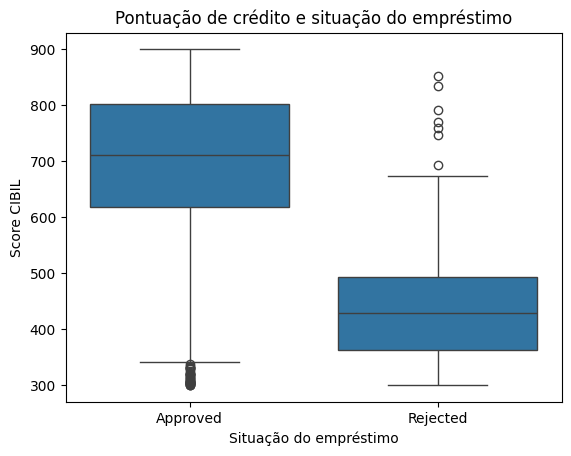

Score mediano por situação:
loan_status
Approved    711.0
Rejected    429.0
Name: cibil_score, dtype: float64


In [6]:
# Gráfico 2: score de crédito por situação
sns.boxplot(data=df, x="loan_status", y="cibil_score", order=["Approved", "Rejected"])
plt.title("Pontuação de crédito e situação do empréstimo")
plt.xlabel("Situação do empréstimo")
plt.ylabel("Score CIBIL")
plt.show()

print("Score mediano por situação:")
print(df.groupby("loan_status")["cibil_score"].median())

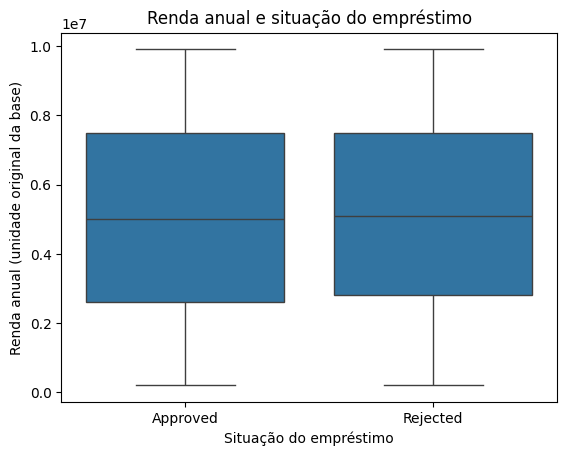

Renda mediana por situação:
loan_status
Approved    5000000.0
Rejected    5100000.0
Name: income_annum, dtype: float64


In [7]:
# Gráfico 3: renda anual por situação
sns.boxplot(data=df, x="loan_status", y="income_annum", order=["Approved", "Rejected"])
plt.title("Renda anual e situação do empréstimo")
plt.xlabel("Situação do empréstimo")
plt.ylabel("Renda anual (unidade original da base)")
plt.show()

print("Renda mediana por situação:")
print(df.groupby("loan_status")["income_annum"].median())

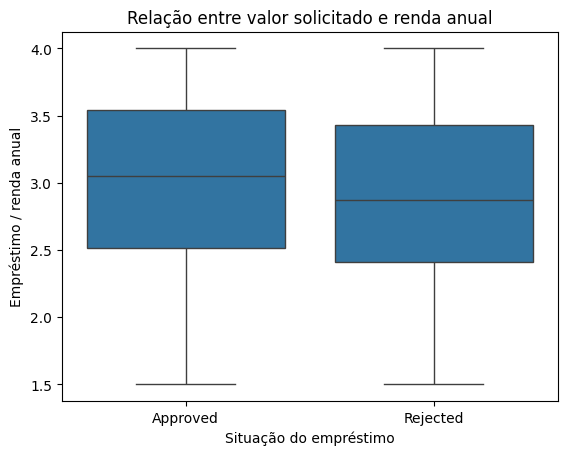

Relação mediana por situação:
loan_status
Approved    3.05
Rejected    2.88
Name: relacao_emprestimo_renda, dtype: float64


In [8]:
# Gráfico 4: valor solicitado / renda anual
# Apenas renda maior que zero permite calcular essa relação
df = df[df["income_annum"] > 0].copy()
df["relacao_emprestimo_renda"] = df["loan_amount"] / df["income_annum"]

sns.boxplot(data=df, x="loan_status", y="relacao_emprestimo_renda", order=["Approved", "Rejected"])
plt.title("Relação entre valor solicitado e renda anual")
plt.xlabel("Situação do empréstimo")
plt.ylabel("Empréstimo / renda anual")
plt.show()

print("Relação mediana por situação:")
print(df.groupby("loan_status")["relacao_emprestimo_renda"].median().round(2))

loan_status   Approved  Rejected
education                       
Graduate          62.5      37.5
Not Graduate      62.0      38.0


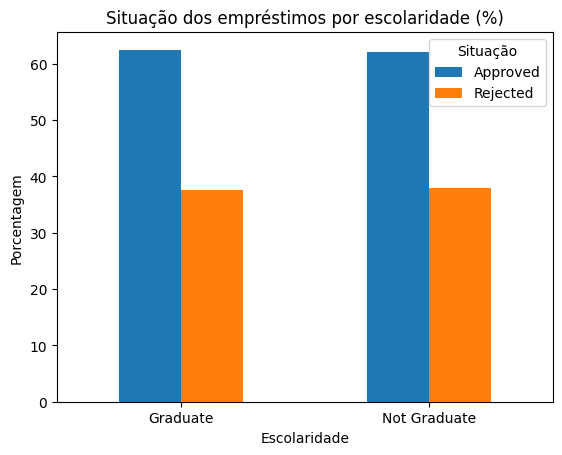

In [9]:
# Gráfico 5: porcentagem de aprovação por escolaridade
tabela = pd.crosstab(df["education"], df["loan_status"], normalize="index") * 100
print(tabela.round(1))

tabela[["Approved", "Rejected"]].plot(kind="bar")
plt.title("Situação dos empréstimos por escolaridade (%)")
plt.xlabel("Escolaridade")
plt.ylabel("Porcentagem")
plt.xticks(rotation=0)
plt.legend(title="Situação")
plt.show()

### Interpretação dos dados

A pontuação de crédito apresentou uma diferença importante entre os empréstimos aprovados e rejeitados. Também analisamos a renda, o valor solicitado e a escolaridade para entender melhor as características dos dois grupos.

## 4. Preparação para Machine Learning

In [10]:
# Fazer uma cópia apenas para o modelo
dados_modelo = df.copy()

# Converter categorias em números
dados_modelo["education"] = dados_modelo["education"].map({"Not Graduate": 0, "Graduate": 1})
dados_modelo["self_employed"] = dados_modelo["self_employed"].map({"No": 0, "Yes": 1})
dados_modelo["loan_status"] = dados_modelo["loan_status"].map({"Rejected": 0, "Approved": 1})

# Conferir se todas as categorias foram convertidas
print(dados_modelo[["education", "self_employed", "loan_status"]].isnull().sum())
assert not dados_modelo[["education", "self_employed", "loan_status"]].isnull().any().any(), "Categoria desconhecida encontrada"

X = dados_modelo.drop(columns=["loan_id", "loan_status"])
y = dados_modelo["loan_status"]

print("Variáveis de entrada:", list(X.columns))
print("Quantidade de exemplos:", len(X))

education        0
self_employed    0
loan_status      0
dtype: int64
Variáveis de entrada: ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'relacao_emprestimo_renda']
Quantidade de exemplos: 4241


## 5. Treinamento da árvore de decisão
Utilizamos uma árvore de decisão, separando 80% dos dados para treinamento e 20% para teste.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

modelo = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo.fit(X_treino, y_treino)

previsoes = modelo.predict(X_teste)

print("Exemplos para treino:", len(X_treino))
print("Exemplos para teste:", len(X_teste))
print("Acurácia do modelo: {:.2%}".format(accuracy_score(y_teste, previsoes)))

Exemplos para treino: 3392
Exemplos para teste: 849
Acurácia do modelo: 99.53%


## 6. Avaliação dos resultados

Relatório de classificação:
              precision    recall  f1-score   support

   Rejeitado       1.00      0.99      0.99       321
    Aprovado       0.99      1.00      1.00       528

    accuracy                           1.00       849
   macro avg       1.00      0.99      0.99       849
weighted avg       1.00      1.00      1.00       849



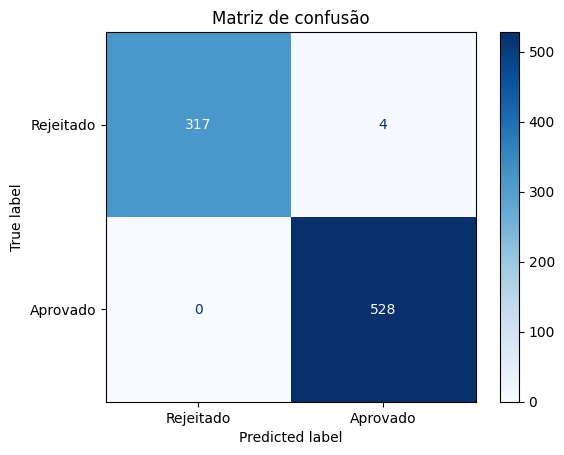

In [12]:
print("Relatório de classificação:")
print(classification_report(y_teste, previsoes, target_names=["Rejeitado", "Aprovado"]))

ConfusionMatrixDisplay.from_predictions(
    y_teste, previsoes, display_labels=["Rejeitado", "Aprovado"], cmap="Blues"
)
plt.title("Matriz de confusão")
plt.show()

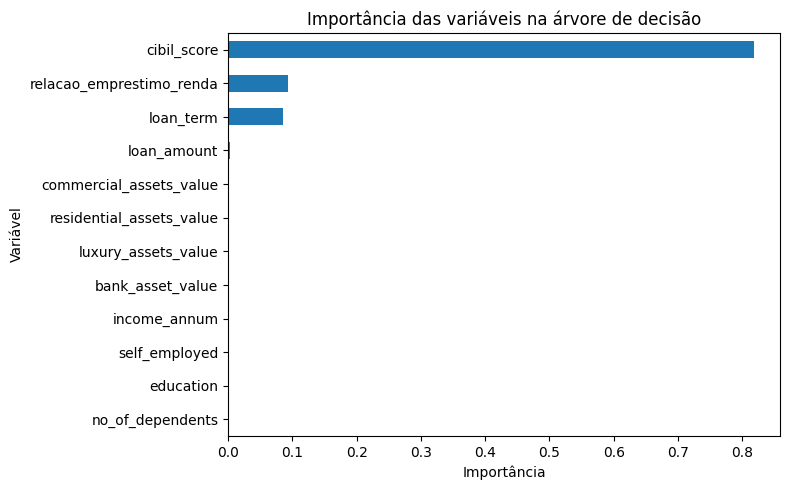

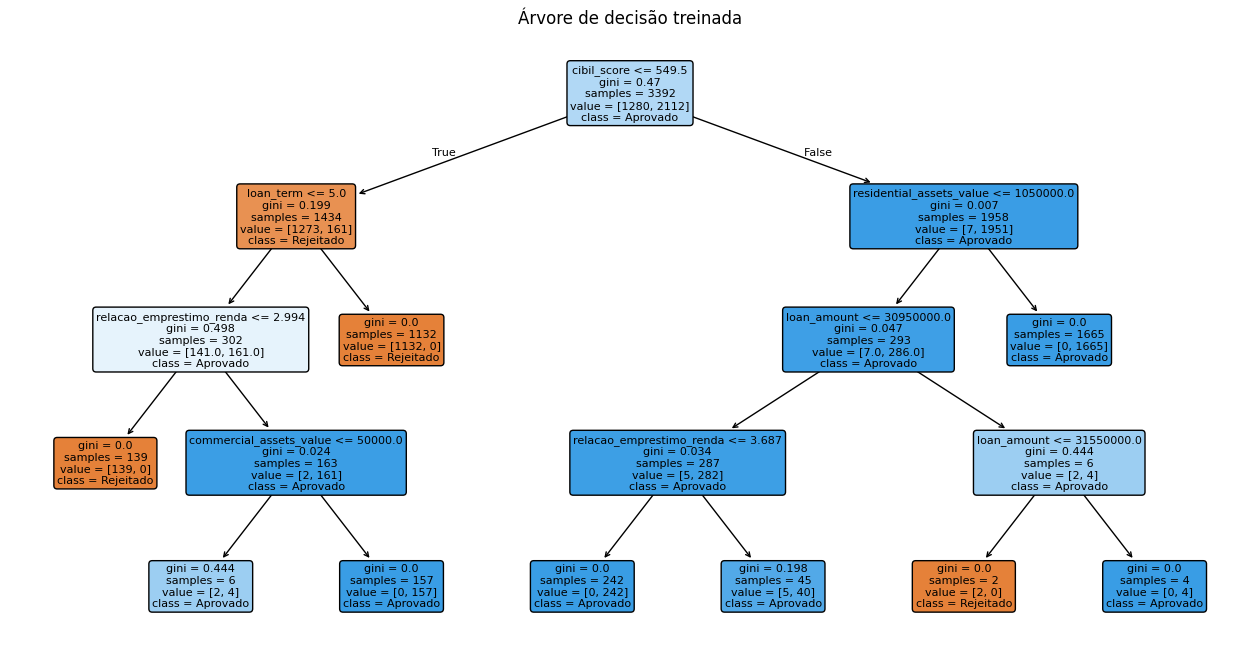

In [13]:
# Importância das variáveis
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
importancias.plot(kind="barh", figsize=(8, 5))
plt.title("Importância das variáveis na árvore de decisão")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

# Árvore de decisão
plt.figure(figsize=(16, 8))
plot_tree(
    modelo, feature_names=X.columns,
    class_names=["Rejeitado", "Aprovado"],
    filled=True, rounded=True, fontsize=8
)
plt.title("Árvore de decisão treinada")
plt.show()

## 7. Conclusão

Com a análise dos dados, identificamos que a pontuação de crédito foi uma das características mais importantes para a aprovação dos empréstimos.

O modelo de árvore de decisão apresentou uma acurácia de 99,53%, acertando 845 das 849 previsões realizadas no conjunto de teste.

Assim, conseguimos aplicar os conceitos estudados na disciplina, desde a preparação e visualização dos dados até a utilização de Machine Learning para realizar classificações.